# Breast Cancer Classification with Neural Networks

Compare a feedforward neural network with logistic regression on the Wisconsin Diagnostic Breast Cancer dataset. The workflow includes stratified splitting, training-only preprocessing, feature selection, a baseline network, hyperparameter search, and evaluation of malignant-class recall.

The outputs below are preserved from the recorded experiment; training has not been rerun during preparation. Numerical results belong to that run. Neural-network training and a fresh hyperparameter search may produce different results.

## 1. Environment and reproducibility

In [ ]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from keras import layers, models
import keras_tuner as kt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.linear_model import LogisticRegression
import warnings
warnings.filterwarnings("ignore")

# Set random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print("All libraries imported successfully!")
print(f"TensorFlow version: {tf.__version__}")
print(f"Keras version: {keras.__version__}")

All libraries imported successfully!
TensorFlow version: 2.19.0
Keras version: 3.10.0


## 2. Dataset and stratified partitions

There are 569 samples and 30 input features: 212 malignant and 357 benign. Labels are **0 = malignant, 1 = benign**. The stratified partitions contain 455 training, 57 validation, and 57 test samples; split seeds are 77 and 2025.

In [ ]:
# Load the breast cancer dataset from scikit-learn
print("\nLoading breast cancer dataset from scikit-learn...")
cancer_data = load_breast_cancer()
X = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
y = pd.Series(cancer_data.target)

print(f"Dataset loaded successfully!")
print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"Feature names: {list(cancer_data.feature_names[:5])}... (showing first 5)")
print(f"Target classes: {cancer_data.target_names}")
print(f"Class distribution: Malignant={sum(y==0)}, Benign={sum(y==1)}")

# Split the data
print("\nCreating stratified train, validation, and test partitions...")

# First split: training+validation vs test (90% vs 10%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.1,
    random_state=77,
    stratify=y
)

# Second split: training vs validation from remaining data
# Validation fraction is adjusted to retain 10% of the original dataset
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.1/(1-0.1),  # This ensures validation is 10% of original data
    random_state=2025,
    stratify=y_temp
)

print(f"Data split completed:")
print(f"Training set: {X_train.shape[0]} samples")
print(f"Validation set: {X_val.shape[0]} samples")
print(f"Test set: {X_test.shape[0]} samples")
print(f"Total samples: {X.shape[0]}")

# Verify stratification
print(f"\nClass distribution verification:")
print(f"Training - Malignant: {sum(y_train==0)}, Benign: {sum(y_train==1)}")
print(f"Validation - Malignant: {sum(y_val==0)}, Benign: {sum(y_val==1)}")
print(f"Test - Malignant: {sum(y_test==0)}, Benign: {sum(y_test==1)}")


Loading breast cancer dataset from scikit-learn...
Dataset loaded successfully!
Features shape: (569, 30)
Target shape: (569,)
Feature names: [np.str_('mean radius'), np.str_('mean texture'), np.str_('mean perimeter'), np.str_('mean area'), np.str_('mean smoothness')]... (showing first 5)
Target classes: ['malignant' 'benign']
Class distribution: Malignant=212, Benign=357

Creating stratified train, validation, and test partitions...
Data split completed:
Training set: 455 samples
Validation set: 57 samples
Test set: 57 samples
Total samples: 569

Class distribution verification:
Training - Malignant: 170, Benign: 285
Validation - Malignant: 21, Benign: 36
Test - Malignant: 21, Benign: 36


## 3. Scaling and feature selection

StandardScaler and SelectKBest (ANOVA F-test, k=10) are fitted on the training partition only. Both models use the same selected, standardized features.

In [ ]:
# Apply StandardScaler on training data to prevent data leakage
print("\nApplying StandardScaler to prevent data leakage...")
print("Fitting scaler on training data only...")

# Initialize and fit scaler only on training data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Transform validation and test sets using the fitted scaler
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f"Training set scaled shape: {X_train_scaled.shape}")
print(f"Validation set scaled shape: {X_val_scaled.shape}")
print(f"Test set scaled shape: {X_test_scaled.shape}")
print("Scaling completed without data leakage!")

# Feature selection on training data only to prevent data leakage
from sklearn.feature_selection import SelectKBest, f_classif

print("\nPerforming feature selection on training data only...")
print("Selecting top 10 features to prevent data leakage...")

# Initialize feature selector
feature_selector = SelectKBest(score_func=f_classif, k=10)

# Fit feature selector ONLY on training data
X_train_selected = feature_selector.fit_transform(X_train_scaled, y_train)

# Transform validation and test sets using the fitted selector
X_val_selected = feature_selector.transform(X_val_scaled)
X_test_selected = feature_selector.transform(X_test_scaled)

# Get selected feature names
selected_features = X.columns[feature_selector.get_support()]
print(f"Selected features: {list(selected_features)}")

# Update datasets with selected features
X_train = pd.DataFrame(X_train_selected, columns=selected_features, index=X_train.index)
X_val = pd.DataFrame(X_val_selected, columns=selected_features, index=X_val.index)
X_test = pd.DataFrame(X_test_selected, columns=selected_features, index=X_test.index)

print(f"Feature selection completed:")
print(f"Training set shape: {X_train.shape}")
print(f"Validation set shape: {X_val.shape}")
print(f"Test set shape: {X_test.shape}")


Applying StandardScaler to prevent data leakage...
Fitting scaler on training data only...
Training set scaled shape: (455, 30)
Validation set scaled shape: (57, 30)
Test set scaled shape: (57, 30)
Scaling completed without data leakage!

Performing feature selection on training data only...
Selecting top 10 features to prevent data leakage...
Selected features: ['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']
Feature selection completed:
Training set shape: (455, 10)
Validation set shape: (57, 10)
Test set shape: (57, 10)


## 4. Baseline network and hyperparameter search

The baseline has four hidden layers of 20 SELU units. RandomSearch explores 2–6 layers, 8–64 units (step 8), and learning rates from 0.0002 to 0.2 on a log scale, with up to 8 trials and 10 epochs per fit. The saved run selected 3 layers × 64 units and a displayed learning rate of 0.002273. Its log shows an existing tuner cache was reloaded; that cache is unavailable here. After final training, the baseline validation accuracy was 1.0000 and the tuned network accuracy was 0.9649. The tuned network is retained for the recorded test comparison; it did not improve validation accuracy.


Building baseline model...

Training baseline model for 10 epochs...
Epoch 1/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step - accuracy: 0.4616 - loss: 0.8763 - val_accuracy: 0.8947 - val_loss: 0.2610
Epoch 2/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9165 - loss: 0.2004 - val_accuracy: 0.8947 - val_loss: 0.1686
Epoch 3/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9387 - loss: 0.1371 - val_accuracy: 0.9123 - val_loss: 0.1291
Epoch 4/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9621 - loss: 0.1143 - val_accuracy: 0.9298 - val_loss: 0.1119
Epoch 5/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9730 - loss: 0.1052 - val_accuracy: 0.9649 - val_loss: 0.1039
Epoch 6/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9690 - loss: 0.1008 - val_accuracy: 0.9825 - val_loss: 0.0994
Epoch 7/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9721 - loss: 0.0982 - val_accuracy: 1.0000 - val_loss: 0.0963
Epoch 8/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 20)             │           220 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,505 (17.60 KB)

 Trainable params: 1,501 (5.86 KB)

...

 Total params: 27,269 (106.52 KB)

 Trainable params: 9,089 (35.50 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 18,180 (71.02 KB)


BASELINE vs BEST MODEL COMPARISON
Baseline Model (4×20 SELU):
  - Validation Accuracy: 1.0000
  - Validation Loss: 0.0901

Best Tuned Model (3×64 SELU):
  - Validation Accuracy: 0.9649
  - Validation Loss: 0.0786

Improvement: -0.0351 accuracy points

Final best model saved as: breast_cancer_ann.keras

Plotting training history for best model...


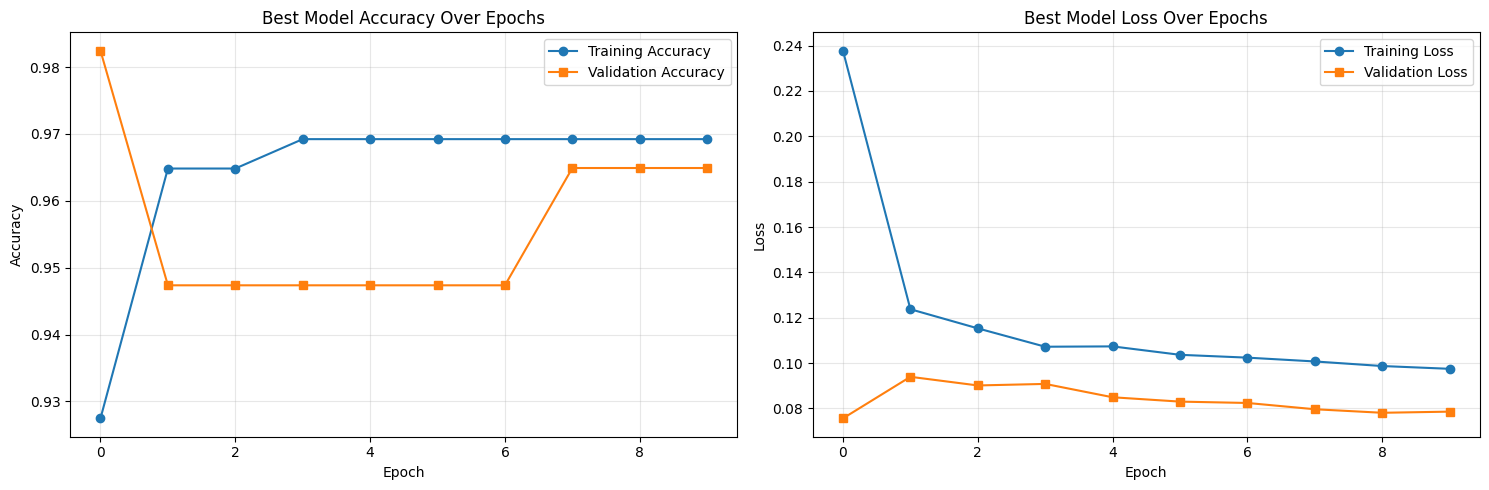

In [ ]:
# Build Baseline Model
print("\nBuilding baseline model...")

def build_baseline_model():
    """
    Builds baseline FNN: 4 hidden layers, 20 nodes each, SELU activation, lecun_normal init
    """
    model = keras.Sequential()

    # Input layer with lecun_normal initialization
    model.add(layers.Dense(20, activation='selu',
                          kernel_initializer='lecun_normal',
                          input_shape=(X_train.shape[1],)))

    # Three additional hidden layers
    for i in range(3):
        model.add(layers.Dense(20, activation='selu',
                              kernel_initializer='lecun_normal'))

    # Output layer
    model.add(layers.Dense(1, activation='sigmoid'))

    # Compile with default learning rate
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

# Train baseline model
print("\nTraining baseline model for 10 epochs...")
baseline_model = build_baseline_model()
baseline_history = baseline_model.fit(
    X_train, y_train,
    epochs=10,
    validation_data=(X_val, y_val),
    verbose=1
)

print("\nBaseline model architecture:")
baseline_model.summary()

# Hyperparameter tuning function
print("\n" + "-"*50)
print("HYPERPARAMETER TUNING SETUP")
print("-"*50)

def build_tuned_model(hp):
    """
    Builds tunable FNN with variable layers (2-6), units (8-64, step 8), and learning rate
    """
    model = keras.Sequential()

    # Tune number of layers (2-6)
    num_layers = hp.Int('num_layers', min_value=2, max_value=6)

    # Tune number of units (8-64, step 8)
    units = hp.Int('units', min_value=8, max_value=64, step=8)

    # Input layer
    model.add(layers.Dense(units, activation='selu',
                          kernel_initializer='lecun_normal',
                          input_shape=(X_train.shape[1],)))

    # Hidden layers
    for i in range(num_layers - 1):
        model.add(layers.Dense(units, activation='selu',
                              kernel_initializer='lecun_normal'))

    # Output layer
    model.add(layers.Dense(1, activation='sigmoid'))

    # Tune learning rate
    learning_rate = hp.Float('learning_rate',
                            min_value=0.0002,
                            max_value=0.2,
                            sampling='log')

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

# Perform hyperparameter tuning
print("\nSetting up Keras RandomSearch tuner...")
tuner = kt.RandomSearch(
    hypermodel=build_tuned_model,
    objective='val_accuracy',
    max_trials=8,
    seed=42,
    directory='my_tuning_dir',
    project_name='breast_cancer_tuning'
)

print("Tuner search space:")
print("- Layers: 2-6")
print("- Units per layer: 8-64 (step 8)")
print("- Learning rate: 0.0002-0.2 (log-uniform)")

print("\nStarting hyperparameter search (8 trials, 10 epochs each)...")
tuner.search(
    x=X_train, y=y_train,
    epochs=10,
    validation_data=(X_val, y_val),
    verbose=1
)

# Get best model
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
best_model = tuner.hypermodel.build(best_hps)

print(f"\nBest hyperparameters found:")
print(f"Number of layers: {best_hps.get('num_layers')}")
print(f"Units per layer: {best_hps.get('units')}")
print(f"Learning rate: {best_hps.get('learning_rate'):.6f}")

# Train best model
print("\nTraining best model with optimal hyperparameters...")
history = best_model.fit(
    X_train, y_train,
    epochs=10,
    validation_data=(X_val, y_val),
    verbose=1
)

print("\nBest model architecture:")
best_model.summary()

# Model comparison
print("\n" + "="*50)
print("BASELINE vs BEST MODEL COMPARISON")
print("="*50)

# Evaluate both models on validation set
baseline_val_loss, baseline_val_acc = baseline_model.evaluate(X_val, y_val, verbose=0)
best_val_loss, best_val_acc = best_model.evaluate(X_val, y_val, verbose=0)

print(f"Baseline Model (4×20 SELU):")
print(f"  - Validation Accuracy: {baseline_val_acc:.4f}")
print(f"  - Validation Loss: {baseline_val_loss:.4f}")

print(f"\nBest Tuned Model ({best_hps.get('num_layers')}×{best_hps.get('units')} SELU):")
print(f"  - Validation Accuracy: {best_val_acc:.4f}")
print(f"  - Validation Loss: {best_val_loss:.4f}")

print(f"\nImprovement: {best_val_acc - baseline_val_acc:.4f} accuracy points")

# Save the final model
model_filename = "breast_cancer_ann.keras"
best_model.save(model_filename)
print(f"\nFinal best model saved as: {model_filename}")

# Plot training history for best model
print("\nPlotting training history for best model...")
plt.figure(figsize=(15, 5))

# Plot accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='s')
plt.title('Best Model Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

# Plot loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss', marker='o')
plt.plot(history.history['val_loss'], label='Validation Loss', marker='s')
plt.title('Best Model Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Neural-network evaluation


This section evaluates the trained FNN model objectively across all datasets.
I will generate predictions, compute classification metrics, and create confusion
matrices to assess performance without clinical interpretation.


Generating predictions for all datasets...
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
Predictions generated successfully!

--------------------------------------------------
CLASSIFICATION REPORTS
--------------------------------------------------

TRAINING SET CLASSIFICATION REPORT:
              precision    recall  f1-score   support

   malignant     0.9877    0.9471    0.9670       170
      benign     0.9692    0.9930    0.9809       285

    accuracy                         0.9758       455
   macro avg     0.9785    0.9700    0.9740       455
weighted avg     0.9761    0.9758    0.9757       455


VALIDATION SET CLASSIFICATION REPORT:
              precision    recall  f1-score   sup

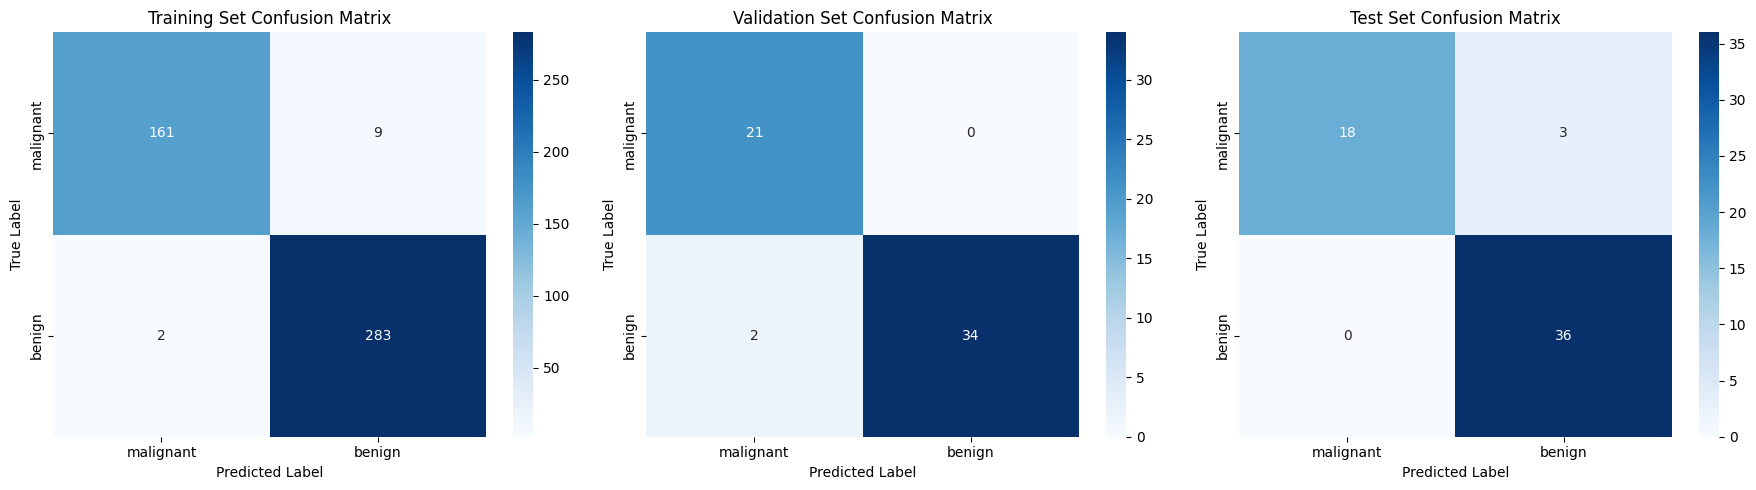


--------------------------------------------------
OBJECTIVE PERFORMANCE SUMMARY
--------------------------------------------------
Training Set Accuracy: 0.9758
Validation Set Accuracy: 0.9649
Test Set Accuracy: 0.9474
Training Set Specificity: 0.9930
Validation Set Specificity: 0.9444
Test Set Specificity: 1.0000

Test Set Complete Metrics Summary:
Malignant Class - Precision: 1.0000, Recall: 0.8571, F1: 0.9231
Benign Class - Precision: 0.9231, Recall: 1.0000, F1: 0.9600
Overall Specificity: 1.0000
Overall Accuracy: 0.9474

Performance Analysis:
Training to Validation degradation: 0.0109
Validation to Test degradation: 0.0175
Overall Training to Test degradation: 0.0285

In [ ]:
print("""
This section evaluates the trained FNN model objectively across all datasets.
I will generate predictions, compute classification metrics, and create confusion
matrices to assess performance without clinical interpretation.
""")

# Generate predictions for all datasets
print("\nGenerating predictions for all datasets...")

# Get probability predictions
y_train_prob = best_model.predict(X_train)
y_val_prob = best_model.predict(X_val)
y_test_prob = best_model.predict(X_test)

# Convert probabilities to binary predictions (threshold = 0.5)
y_train_pred = (y_train_prob > 0.5).astype(int).flatten()
y_val_pred = (y_val_prob > 0.5).astype(int).flatten()
y_test_pred = (y_test_prob > 0.5).astype(int).flatten()

print("Predictions generated successfully!")

# Classification Reports
print("\n" + "-"*50)
print("CLASSIFICATION REPORTS")
print("-"*50)

print("\nTRAINING SET CLASSIFICATION REPORT:")
train_report = classification_report(
    y_train, y_train_pred,
    target_names=['malignant', 'benign'],
    digits=4
)
print(train_report)

print("\nVALIDATION SET CLASSIFICATION REPORT:")
val_report = classification_report(
    y_val, y_val_pred,
    target_names=['malignant', 'benign'],
    digits=4
)
print(val_report)

print("\nTEST SET CLASSIFICATION REPORT:")
test_report = classification_report(
    y_test, y_test_pred,
    target_names=['malignant', 'benign'],
    digits=4
)
print(test_report)

# Confusion Matrices
print("\n" + "-"*50)
print("CONFUSION MATRICES")
print("-"*50)

# Create confusion matrices
train_cm = confusion_matrix(y_train, y_train_pred)
val_cm = confusion_matrix(y_val, y_val_pred)
test_cm = confusion_matrix(y_test, y_test_pred)

# Plot confusion matrices
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Training set confusion matrix
sns.heatmap(train_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['malignant', 'benign'],
            yticklabels=['malignant', 'benign'],
            ax=axes[0])
axes[0].set_title('Training Set Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# Validation set confusion matrix
sns.heatmap(val_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['malignant', 'benign'],
            yticklabels=['malignant', 'benign'],
            ax=axes[1])
axes[1].set_title('Validation Set Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

# Test set confusion matrix
sns.heatmap(test_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['malignant', 'benign'],
            yticklabels=['malignant', 'benign'],
            ax=axes[2])
axes[2].set_title('Test Set Confusion Matrix')
axes[2].set_xlabel('Predicted Label')
axes[2].set_ylabel('True Label')

plt.tight_layout()
plt.show()

# Objective Performance Summary
print("\n" + "-"*50)
print("OBJECTIVE PERFORMANCE SUMMARY")
print("-"*50)

# Calculate accuracy for each set
train_accuracy = (train_cm[0,0] + train_cm[1,1]) / np.sum(train_cm)
val_accuracy = (val_cm[0,0] + val_cm[1,1]) / np.sum(val_cm)
test_accuracy = (test_cm[0,0] + test_cm[1,1]) / np.sum(test_cm)

print(f"Training Set Accuracy: {train_accuracy:.4f}")
print(f"Validation Set Accuracy: {val_accuracy:.4f}")
print(f"Test Set Accuracy: {test_accuracy:.4f}")

# Extract key metrics from classification reports for objective analysis
from sklearn.metrics import precision_recall_fscore_support

# Test set detailed metrics
test_precision, test_recall, test_f1, test_support = precision_recall_fscore_support(
    y_test, y_test_pred, average=None, labels=[0, 1]
)


def calculate_specificity(cm):
    """
    Calculate specificity = TN / (TN + FP) for malignant class
    For malignant class (class 0): TN is position [1,1], FP is position [1,0]
    """
    tn = cm[1, 1]  # True Negatives (correctly identified benign)
    fp = cm[1, 0]  # False Positives (benign predicted as malignant)

    if (tn + fp) == 0:
        return 0.0

    specificity = tn / (tn + fp)
    return specificity

# Calculate specificity for all datasets
train_specificity = calculate_specificity(train_cm)
val_specificity = calculate_specificity(val_cm)
test_specificity = calculate_specificity(test_cm)

print(f"Training Set Specificity: {train_specificity:.4f}")
print(f"Validation Set Specificity: {val_specificity:.4f}")
print(f"Test Set Specificity: {test_specificity:.4f}")


print(f"\nTest Set Complete Metrics Summary:")
print(f"Malignant Class - Precision: {test_precision[0]:.4f}, Recall: {test_recall[0]:.4f}, F1: {test_f1[0]:.4f}")
print(f"Benign Class - Precision: {test_precision[1]:.4f}, Recall: {test_recall[1]:.4f}, F1: {test_f1[1]:.4f}")
print(f"Overall Specificity: {test_specificity:.4f}")
print(f"Overall Accuracy: {test_accuracy:.4f}")


# Performance degradation analysis
print(f"\nPerformance Analysis:")
print(f"Training to Validation degradation: {train_accuracy - val_accuracy:.4f}")
print(f"Validation to Test degradation: {val_accuracy - test_accuracy:.4f}")
print(f"Overall Training to Test degradation: {train_accuracy - test_accuracy:.4f}")

## 6. Logistic regression comparison

Training logistic regression baseline...

Logistic Regression Test Set Performance:
              precision    recall  f1-score   support

   malignant     1.0000    0.8095    0.8947        21
      benign     0.9000    1.0000    0.9474        36

    accuracy                         0.9298        57
   macro avg     0.9500    0.9048    0.9211        57
weighted avg     0.9368    0.9298    0.9280        57



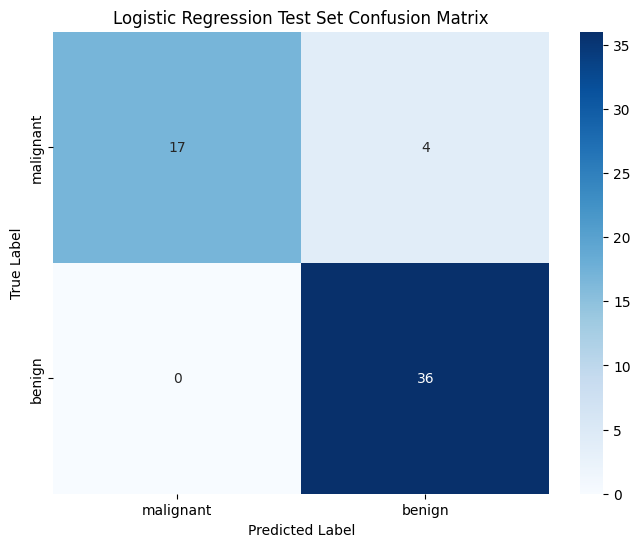


MODEL COMPARISON:
Neural Network Test Accuracy: 0.9474
Logistic Regression Test Accuracy: 0.9298
Difference: 0.0175


In [ ]:
# Build and train logistic regression model
print("\nTraining logistic regression baseline...")

# Create logistic regression model
logreg_model = LogisticRegression(
    C=1,                           # Regularization strength
    class_weight={0: 0.4, 1: 0.6}, # Malignant: 0.4, Benign: 0.6
    penalty='l2',                  # L2 regularization
    solver='lbfgs',               # Solver
    random_state=42               # For reproducibility
)

# Train the logistic regression model
logreg_model.fit(X_train, y_train)

# Generate predictions
logreg_pred = logreg_model.predict(X_test)

print("\nLogistic Regression Test Set Performance:")
logreg_report = classification_report(
    y_test, logreg_pred,
    target_names=['malignant', 'benign'],
    digits=4
)
print(logreg_report)

# Logistic regression confusion matrix
logreg_cm = confusion_matrix(y_test, logreg_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(logreg_cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['malignant', 'benign'],
            yticklabels=['malignant', 'benign'])
plt.title('Logistic Regression Test Set Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

# Model comparison
logreg_accuracy = (logreg_cm[0,0] + logreg_cm[1,1]) / np.sum(logreg_cm)
print(f"\nMODEL COMPARISON:")
print(f"Neural Network Test Accuracy: {test_accuracy:.4f}")
print(f"Logistic Regression Test Accuracy: {logreg_accuracy:.4f}")
print(f"Difference: {test_accuracy - logreg_accuracy:.4f}")

## 7. Results and interpretation

| Test metric | Neural network | Logistic regression |
|---|---:|---:|
| Accuracy | 0.9474 | 0.9298 |
| Malignant precision | 1.0000 | 1.0000 |
| Malignant recall | 0.8571 | 0.8095 |
| Malignant F1 | 0.9231 | 0.8947 |
| Benign recall / specificity for malignant detection | 1.0000 | 1.0000 |

The test partition contains 21 malignant and 36 benign samples. With malignant disease treated as the clinical positive condition, the network missed 3 malignant cases and logistic regression missed 4. Neither classified a benign test sample as malignant. Matrices use the original label order [malignant, benign], so the network matrix is [[18, 3], [0, 36]] and the logistic regression matrix is [[17, 4], [0, 36]]. The original class-1-oriented error labels were replaced with this explicit clinical interpretation; predictions and numerical outputs are unchanged.

The network classified one additional test sample correctly. A single split with 57 test samples does not establish a reliable general advantage. Hyperparameter selection used validation accuracy rather than malignant recall, and the tuned network's final validation accuracy was lower than the baseline's. Model complexity, interpretability, calibration, and missed malignant cases remain relevant considerations.

This is an exploratory benchmark. External validation, repeated evaluation, probability calibration, and a threshold policy chosen using validation data would be needed before considering clinical use. These steps were not performed in this recorded experiment. The repository does not contain fitted weights, scaler state, feature-selector state, tuner history, or individual prediction probabilities.